# Étape 2 — Transformation et préparation des données

Objectif : préparer les données pour l'entraînement des modèles, en garantissant **l'absence de data leakage** :

1. séparation train / test (80 % / 20 %) **avant toute transformation** ;
2. imputation des valeurs manquantes ;
3. détection et traitement des valeurs aberrantes (IQR) ;
4. encodage des variables catégorielles ;
5. vérification du déséquilibre des classes (SMOTE si nécessaire) ;
6. standardisation des variables numériques ;
7. regroupement de toutes les transformations dans un **pipeline** fit sur le train uniquement.

Constats issus de l'EDA (étape 1) :

- 2 000 lignes × 17 colonnes, **0 doublon**, pas d'incohérence dans les catégories ;
- ~2 à 4,5 % de valeurs manquantes sur 7 colonnes (aucune colonne > 5 %) ;
- cible `Mental_Health_Risk` en 3 classes **quasi équilibrées** (~33 % chacune) ;
- quelques outliers IQR sur les variables numériques (valeurs extrêmes mais plausibles) ;
- `Student_ID` = simple identifiant, sans valeur prédictive → à exclure.

## 1. Imports et chargement des données

On charge le CSV brut et on sépare d'emblée les variables explicatives (`X`) de la cible (`y`).
`Student_ID` est retiré : c'est un identifiant technique sans lien avec le risque, le garder n'apporterait que du bruit (risque de sur-apprentissage sur une colonne unique par ligne).

In [2]:
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder

from preprocessing_utils import IQRCapper

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

DATASETPATH = Path.cwd() / "Data" / "student_mental_health.csv"
OUTDIR = Path.cwd() / "Data" / "processed"
OUTDIR.mkdir(exist_ok=True)

TARGET = "Mental_Health_Risk"
DROP_COLS = ["Student_ID"]

df = pd.read_csv(DATASETPATH)
df = df.drop(columns=DROP_COLS)

X = df.drop(columns=[TARGET])
y = df[TARGET]

print(f"X : {X.shape} | y : {y.shape}")
X.head()

X : (2000, 15) | y : (2000,)


,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History
0,22,Male,3,6.6,17.6,2.91,6.9,7.5,Moderate,8.5,4.0,78.0,No,Poor,No
1,21,Male,4,5.6,22.4,2.92,7.6,11.5,Low,4.5,5.3,85.4,Yes,Average,No
2,22,Male,5,7.1,28.1,2.68,6.5,8.9,Low,4.8,6.1,79.5,No,Average,No
3,24,Male,1,4.5,14.8,2.23,5.5,7.6,High,3.7,8.0,73.9,No,Average,Yes
4,20,Female,1,6.7,17.2,2.69,4.3,7.0,Moderate,8.0,7.4,99.8,Yes,NaN,No


## 2. Séparation train / test (80 % / 20 %)

**Décision :** on sépare **avant toute transformation** (imputation, clipping, encodage, scaling). C'est la règle anti data leakage fondamentale : tout ce qui "apprend" des données (moyennes d'imputation, bornes IQR, catégories, moyennes/écarts-types du scaler) doit être calculé **uniquement sur le train**, puis simplement appliqué au test. Le jeu de test joue alors le rôle de données réellement inédites.

**Décision :** `stratify=y`. La cible étant une classification à 3 classes, la stratification garantit que train et test ont la même répartition (~33/33/34), indispensable pour des comparaisons fiables avec un jeu de cette taille.

**Décision :** `random_state=42` pour la reproductibilité (les mêmes splits à chaque exécution, notebook, DAG Airflow et app).

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

print(f"Train : {X_train.shape[0]} lignes | Test : {X_test.shape[0]} lignes")
print()
print("Répartition de la cible :")
repartition = pd.DataFrame({
    "train %": (y_train.value_counts(normalize=True) * 100).round(1),
    "test %": (y_test.value_counts(normalize=True) * 100).round(1),
})
print(repartition)

Train : 1600 lignes | Test : 400 lignes

Répartition de la cible :
                    train %  test %
Mental_Health_Risk                 
High                   34.0    34.0
Medium                 33.0    33.0
Low                    33.0    33.0


## 3. Valeurs manquantes — choix de la méthode d'imputation

Rappel de l'EDA : 7 colonnes ont entre ~2 % et ~4,5 % de valeurs manquantes, et uniquement **complètement au hasard** (aucun pattern identifiable). Aucune colonne n'est assez vide pour justifier une suppression (> 40 %).

**Décision :**
- **Variables numériques → imputation par la médiane.** La médiane est robuste aux outliers et aux distributions asymétriques (contrairement à la moyenne) : plusieurs de ces variables ont des outliers IQR détectés à l'EDA, la moyenne serait tirée par ces valeurs extrêmes.
- `Diet_Quality` (seule catégorielle concernée) → **modalité la plus fréquente.** Avec seulement ~3,5 % de manquants, imputer par la modalité dominante (`Average`) déforme très peu la distribution, et cela reste compatible avec son encodage ordinal.

⚠️ Ces imputations sont réalisées **dans le pipeline** (section 8) : les médianes / modes sont appris sur le train seul, jamais sur l'ensemble des données.

Vérification des manquants sur le train :

In [4]:
missing_train = (
    pd.DataFrame({
        "manquants": X_train.isna().sum(),
        "pct": (X_train.isna().mean() * 100).round(2),
    })
    .query("manquants > 0")
    .sort_values("manquants", ascending=False)
)
missing_train

,manquants,pct
Financial_Stress,76,4.75
Diet_Quality,55,3.44
Sleep_Hours,54,3.38
Social_Media_Hours,48,3.00
Attendance_Rate,39,2.44
GPA,36,2.25
Family_Support,36,2.25


**Listes des colonnes par type** (numériques, nominales, ordinales) utilisées par le pipeline, et contrôle que la cible ne contient aucun manquant.

In [5]:
NUMERIC_COLS = ["Age", "Sleep_Hours", "Study_Hours_Per_Week", "GPA", "Social_Media_Hours",
                "Screen_Time_Hours", "Financial_Stress", "Family_Support", "Attendance_Rate"]
NOMINAL_COLS = ["Gender", "Physical_Activity", "Part_Time_Job", "Previous_Mental_Health_History"]
ORDINAL_COLS = ["Diet_Quality"]  # ordre naturel : Poor < Average < Good

# Vérification : la cible ne contient aucun manquant
print(f"Manquants dans y_train : {y_train.isna().sum()} | dans y_test : {y_test.isna().sum()}")

Manquants dans y_train : 0 | dans y_test : 0


## 4. Valeurs aberrantes — détection IQR et traitement par winsorisation

### Détection (règle de l'IQR)

Une valeur est considérée comme aberrante si elle sort de `[Q1 − 1.5·IQR ; Q3 + 1.5·IQR]`. On détecte sur le **train uniquement** :

In [6]:
def iqr_bounds(series, factor=1.5):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - factor * iqr, q3 + factor * iqr

rows = []
for col in NUMERIC_COLS:
    lo, hi = iqr_bounds(X_train[col])
    n_out = ((X_train[col] < lo) | (X_train[col] > hi)).sum()
    rows.append({
        "colonne": col,
        "borne_basse": round(lo, 2),
        "borne_haute": round(hi, 2),
        "outliers": n_out,
        "pct": round(n_out / len(X_train) * 100, 2),
    })

outliers_df = pd.DataFrame(rows).sort_values("outliers", ascending=False)
outliers_df

,colonne,borne_basse,borne_haute,outliers,pct
4,Social_Media_Hours,3.05,9.05,10,0.62
8,Attendance_Rate,65.35,104.95,10,0.62
1,Sleep_Hours,3.75,9.75,9,0.56
5,Screen_Time_Hours,3.95,13.15,7,0.44
2,Study_Hours_Per_Week,4.00,36.00,7,0.44
3,GPA,1.60,3.52,5,0.31
0,Age,15.50,27.50,2,0.12
6,Financial_Stress,0.15,11.75,0,0.00
7,Family_Support,1.00,12.20,0,0.00


### Décision de traitement : winsorisation (clipping), pas de suppression

**Justification :**
1. **Les outliers sont plausibles, pas des erreurs.** À l'EDA, on a vérifié les min/max physiques : GPA reste dans [1.5 ; 4], le taux de présence dans [0 ; 100], les âges dans une plage raisonnable. Ce sont de vrais étudiants aux habitudes extrêmes — des profils **justement intéressants** pour un modèle de risque.
2. **Supprimer les lignes ferait perdre de l'information** et biaiserait l'échantillon (on éliminerait des cas atypiques, potentiellement les plus informative pour la classe "High").
3. **Le clipping limite leur influence** sans les exclure : les valeurs au-delà des bornes sont ramenées à la borne. C'est un bon compromis, surtout pour les modèles sensibles aux échelles (régression logistique, KNN).
4. **Data leakage évité** : les bornes sont calculées dans le pipeline sur le train, puis appliquées telles quelles au test.

On implémente le clipping comme un transformateur sklearn custom (`IQRCapper`, défini dans `preprocessing_utils.py` pour pouvoir le sérialiser/recharger proprement) :

In [7]:
# Impact du clipping sur le train : nombre de valeurs modifiées par colonne
capper_fit = IQRCapper().fit(X_train[NUMERIC_COLS])
X_train_num_clipped = capper_fit.transform(X_train[NUMERIC_COLS])
n_modified = (X_train[NUMERIC_COLS].to_numpy() != X_train_num_clipped).sum(axis=0)

pd.DataFrame(
    {"valeurs_clippées": n_modified.astype(int)},
    index=NUMERIC_COLS,
).sort_values("valeurs_clippées", ascending=False).query("valeurs_clippées > 0")

,valeurs_clippées
Financial_Stress,76
Sleep_Hours,63
Social_Media_Hours,58
Attendance_Rate,49
GPA,41
Family_Support,36
Study_Hours_Per_Week,7
Screen_Time_Hours,7
Age,2


**Visuel** — effet du clipping sur la distribution des 2 variables les plus concernées.

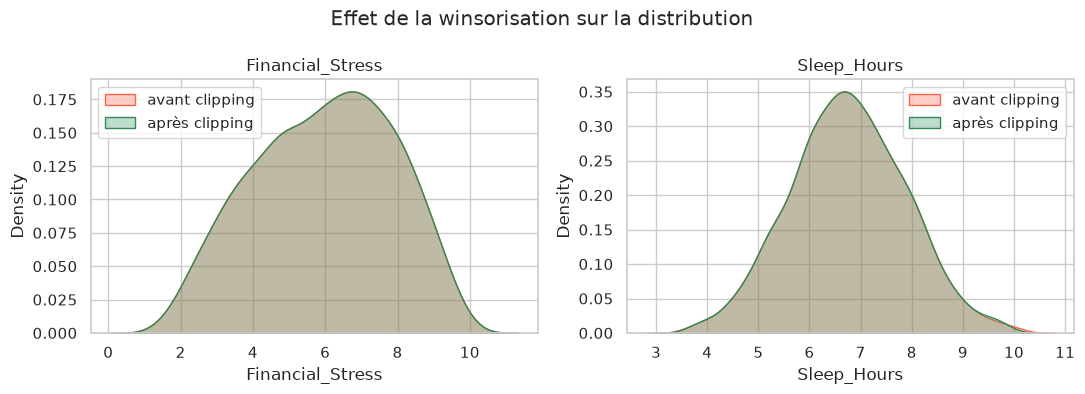

In [8]:
# Visuel : effet du clipping sur les 2 variables les plus concernées
worst = (
    pd.DataFrame({"valeurs_clippées": n_modified.astype(int)}, index=NUMERIC_COLS)
    .sort_values("valeurs_clippées", ascending=False)
    .head(2)
    .index.tolist()
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, col in zip(axes, worst):
    before = X_train[col]
    after = pd.Series(X_train_num_clipped[:, NUMERIC_COLS.index(col)], index=before.index)
    sns.kdeplot(before, ax=ax, label="avant clipping", color="tomato", fill=True, alpha=0.3)
    sns.kdeplot(after, ax=ax, label="après clipping", color="seagreen", fill=True, alpha=0.3)
    ax.set_title(col)
    ax.legend()
fig.suptitle("Effet de la winsorisation sur la distribution")
plt.tight_layout()
plt.show()

## 5. Encodage des variables catégorielles

**Décision, variable par variable :**

| Variable | Type | Encodage | Justification |
|---|---|---|---|
| `Gender`, `Physical_Activity`, `Part_Time_Job`, `Previous_Mental_Health_History` | Nominale (aucun ordre) | **One-Hot Encoder** | Créer un ordre artificiel (Male=0, Female=1…) ferait croire au modèle qu'une modalité est "plus grande" qu'une autre. Le one-hot traite chaque modalité comme une dimension binaire indépendante. |
| `Diet_Quality` | Ordinale (Poor < Average < Good) | **Ordinal Encoder** (ordre explicite) | Il existe un ordre naturel et une seule colonne préserve cette information sans gonfler la dimensionnalité. |
| `Year_of_Study` | Déjà numérique (1→5) | Rien à faire | C'est déjà un entier ordinal. |

**Robustesse :** `handle_unknown="ignore"` sur le OneHot : si l'app Streamlit ou le DAG reçoit un jour une modalité jamais vue à l'entraînement, toutes ses colonnes one-hot passent à 0 au lieu de faire planter le pipeline.

In [9]:
# Ordre explicite pour l'encodage ordinal de Diet_Quality
DIET_ORDER = ["Poor", "Average", "Good"]

## 6. Déséquilibre des classes — SMOTE nécessaire ?

**Décision : pas de rééchantillonnage.** L'EDA a montré une répartition ~33/33/34. On le reconfirme sur le train :

In [10]:
distribution = (
    pd.DataFrame({
        "n": y_train.value_counts(),
        "pct": (y_train.value_counts(normalize=True) * 100).round(2),
    })
)
print(distribution)
print()
imbalance_ratio = distribution["n"].max() / distribution["n"].min()
print(f"Ratio de déséquilibre (classe max / classe min) : {imbalance_ratio:.2f}")
print()
print("Seuil habituel d'intervention : ratio >= 2 (ex. 80/20). Ici ~1.0 -> classes équilibrées.")
print("=> SMOTE / undersampling inutiles : appliquer du sur-échantillonnage artificiel")
print("   sur des classes déjà équilibrées n'apporte rien et risque de créer des points synthétiques non réalistes.")

                      n   pct
Mental_Health_Risk           
High                544  34.0
Medium              528  33.0
Low                 528  33.0

Ratio de déséquilibre (classe max / classe min) : 1.03

Seuil habituel d'intervention : ratio >= 2 (ex. 80/20). Ici ~1.0 -> classes équilibrées.
=> SMOTE / undersampling inutiles : appliquer du sur-échantillonnage artificiel
   sur des classes déjà équilibrées n'apporte rien et risque de créer des points synthétiques non réalistes.


**Contrôle visuel** de la répartition de la cible dans le train.

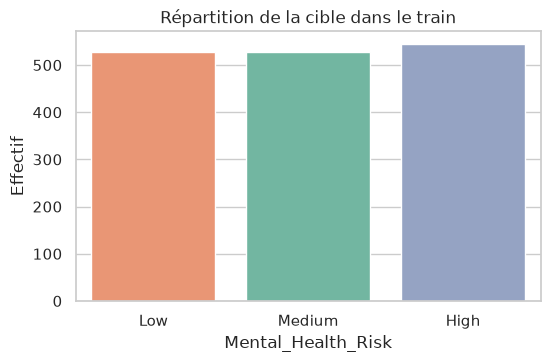

In [11]:
# Contrôle visuel de la répartition dans le train
fig, ax = plt.subplots(figsize=(6, 3.5))
sns.countplot(x=y_train, order=["Low", "Medium", "High"], hue=y_train,
              palette="Set2", legend=False, ax=ax)
ax.set_title("Répartition de la cible dans le train")
ax.set_ylabel("Effectif")
plt.show()

## 7. Standardisation des variables numériques

**Décision : StandardScaler** (centrage-réduction : moyenne 0, écart-type 1), appliqué **après** imputation et clipping, **dans le pipeline** (moyennes et écarts-types appris sur le train seul).

**Justification :** les échelles sont très hétérogènes — `GPA` ≈ 0–4, `Age` ≈ 17–29, `Attendance_Rate` ≈ 54–100, `Financial_Stress` ≈ 1–10. Sans standardisation, les modèles basés sur les distances (KNN) ou la régularisation (régression logistique, SVM) seraient dominés par les variables à grande échelle. Les modèles d'arbres y sont insensibles, mais le même pipeline servira à tous, donc on standardise systématiquement.

On garde le clipping en amont du scaler pour que les valeurs extrêmes n'écrasent pas le calcul de moyenne/écart-type.

## 8. Pipeline complet de prétraitement (anti data leakage)

Toutes les transformations sont assemblées dans un `ColumnTransformer` :

- **Branche numérique** : `IQRCapper` → `SimpleImputer(median)` → `StandardScaler`
- **Branche nominale** : `SimpleImputer(most_frequent)` → `OneHotEncoder(handle_unknown="ignore")`
- **Branche ordinale** : `SimpleImputer(most_frequent)` → `OrdinalEncoder(ordre explicite)`

L'ordre **imputation → clipping → scaling** est important : l'imputeur doit d'abord combler les trous (le scaler n'accepte pas les NaN, et le clipper ne doit pas clipper des NaN), puis le clipping borne les valeurs, puis le scaling normalise le tout.

Un seul `fit` sur `X_train`, puis le test est uniquement `transformé` : aucune statistique (bornes, médianes, modes, moyennes, écarts-types, catégories) n'est jamais calculée sur le test.

In [12]:
numeric_pipeline = Pipeline(steps=[
    ("iqr_clip", IQRCapper(factor=1.5)),
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

nominal_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

ordinal_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("ordinal", OrdinalEncoder(categories=[DIET_ORDER],
                               handle_unknown="use_encoded_value", unknown_value=-1)),
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_pipeline, NUMERIC_COLS),
    ("nom", nominal_pipeline, NOMINAL_COLS),
    ("ord", ordinal_pipeline, ORDINAL_COLS)],
    remainder="passthrough",   # Year_of_Study passe sans transformation
    verbose_feature_names_out=True,
)

preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('nom', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``fe

**Application du pipeline** — `fit` sur le train uniquement, puis simple `transform` du test.

In [13]:
# Fit sur le TRAIN uniquement, puis simple transformation du test
X_train_prepared = preprocessor.fit_transform(X_train)
X_test_prepared = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()
print(f"Dimensions avant encodage  : {X_train.shape}")
print(f"Dimensions après pipeline  : {X_train_prepared.shape} (train) / {X_test_prepared.shape} (test)")
print()
print("Variables générées :")
for name in feature_names:
    print("  -", name)

Dimensions avant encodage  : (1600, 15)
Dimensions après pipeline  : (1600, 21) (train) / (400, 21) (test)

Variables générées :
  - num__Age
  - num__Sleep_Hours
  - num__Study_Hours_Per_Week
  - num__GPA
  - num__Social_Media_Hours
  - num__Screen_Time_Hours
  - num__Financial_Stress
  - num__Family_Support
  - num__Attendance_Rate
  - nom__Gender_Female
  - nom__Gender_Male
  - nom__Gender_Non-binary
  - nom__Physical_Activity_High
  - nom__Physical_Activity_Low
  - nom__Physical_Activity_Moderate
  - nom__Part_Time_Job_No
  - nom__Part_Time_Job_Yes
  - nom__Previous_Mental_Health_History_No
  - nom__Previous_Mental_Health_History_Yes
  - ord__Diet_Quality
  - remainder__Year_of_Study


**Contrôles qualité** — absence de NaN, moyennes/écarts-types des colonnes standardisées ≈ 0 / 1, aperçu sous forme de DataFrame.

In [14]:
# Contrôles qualité du résultat
print(f"NaN restants train : {np.isnan(X_train_prepared).sum()} | test : {np.isnan(X_test_prepared).sum()}")
print(f"Moyenne des colonnes numériques standardisées (train) ~ 0 : {np.abs(X_train_prepared[:, :9].mean(axis=0)).max():.2e}")
print(f"Écart-type des colonnes numériques standardisées (train) ~ 1 : {np.abs(X_train_prepared[:, :9].std(axis=0) - 1).max():.2e}")
print()
# Aperçu sous forme de DataFrame pour lisibilité
X_train_prepared_df = pd.DataFrame(X_train_prepared, columns=feature_names)
X_train_prepared_df.head()

NaN restants train : 0 | test : 0
Moyenne des colonnes numériques standardisées (train) ~ 0 : 2.24e-14
Écart-type des colonnes numériques standardisées (train) ~ 1 : 4.88e-15



,num__Age,num__Sleep_Hours,num__Study_Hours_Per_Week,num__GPA,num__Social_Media_Hours,num__Screen_Time_Hours,num__Financial_Stress,num__Family_Support,num__Attendance_Rate,nom__Gender_Female,nom__Gender_Male,nom__Gender_Non-binary,nom__Physical_Activity_High,nom__Physical_Activity_Low,nom__Physical_Activity_Moderate,nom__Part_Time_Job_No,nom__Part_Time_Job_Yes,nom__Previous_Mental_Health_History_No,nom__Previous_Mental_Health_History_Yes,ord__Diet_Quality,remainder__Year_of_Study
0,-0.063471,-1.407010,-0.239251,0.074785,0.150817,1.102483,0.713748,0.643008,-1.260010,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,1.0,2.0
1,0.876838,-1.679538,-1.334412,-0.977908,0.331233,0.195167,-0.842691,0.368687,-0.473398,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0
2,-1.003780,0.409842,-0.517387,-1.036391,-0.300224,-0.833123,-0.305988,0.752736,0.776753,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,1.0,2.0
3,0.876838,1.409111,-0.082800,0.893546,0.782274,1.102483,0.821088,-0.948052,-0.220559,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,1.0,1.0
4,0.406684,0.409842,0.664691,-0.276113,-0.390432,-0.349222,0.660077,0.697872,-1.470710,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,3.0


### Vérification anti data leakage

Le test est transformé avec **les statistiques du train** : on le prouve en comparant les moyennes/écarts-types des colonnes numériques — sur le test, elles ne sont plus exactement 0 et 1 (c'est attendu et souhaité) :

In [15]:
X_test_prepared_df = pd.DataFrame(X_test_prepared, columns=feature_names)

verification = pd.DataFrame({
    "train_mean": X_train_prepared_df.iloc[:, :9].mean().round(3),
    "test_mean": X_test_prepared_df.iloc[:, :9].mean().round(3),
    "train_std": X_train_prepared_df.iloc[:, :9].std().round(3),
    "test_std": X_test_prepared_df.iloc[:, :9].std().round(3),
})
verification

,train_mean,test_mean,train_std,test_std
num__Age,-0.0,-0.012,1.0,1.017
num__Sleep_Hours,0.0,0.035,1.0,1.024
num__Study_Hours_Per_Week,0.0,0.019,1.0,0.960
num__GPA,-0.0,-0.031,1.0,0.970
num__Social_Media_Hours,-0.0,-0.090,1.0,1.077
num__Screen_Time_Hours,-0.0,-0.087,1.0,0.997
num__Financial_Stress,-0.0,-0.020,1.0,0.965
num__Family_Support,0.0,-0.013,1.0,0.992
num__Attendance_Rate,-0.0,0.020,1.0,0.973


## 9. Sauvegarde des artefacts

On sauvegarde :
- le **préprocesseur ajusté** (`.pkl`) — il sera rechargé tel quel par l'app Streamlit et le DAG Airflow pour prétraiter les nouvelles données exactement comme à l'entraînement ;
- les **jeux transformés** + cibles (`.pkl`) pour l'étape 3 (entraînement et comparaison des modèles).

In [16]:
joblib.dump(preprocessor, OUTDIR / "preprocessor.pkl")
joblib.dump({"X_train": X_train_prepared, "X_test": X_test_prepared,
             "y_train": y_train, "y_test": y_test,
             "feature_names": feature_names}, OUTDIR / "split_data.pkl")

print("Fichiers sauvegardés dans", OUTDIR)
for f in sorted(OUTDIR.iterdir()):
    print(f"  - {f.name} ({f.stat().st_size / 1024:.1f} Ko)")

Fichiers sauvegardés dans /home/bahaztariq/Youcode/mental/src/mental/Data/processed
  - preprocessor.pkl (6.3 Ko)
  - split_data.pkl (365.7 Ko)


## 10. Synthèse des décisions de préparation

| Étape | Décision | Justification |
|---|---|---|
| Split | 80/20 stratifié, `random_state=42`, **avant toute transformation** | Test = données inédites ; stratification conserve ~33/33/34 dans chaque ensemble ; reproductibilité |
| Colonnes | Suppression de `Student_ID` | Identifiant sans valeur prédictive, source de bruit / sur-apprentissage |
| Manquants | Médiane (numériques), modalité la plus fréquente (`Diet_Quality`) | Médiane robuste aux outliers ; ~2–4,5 % de manquants seulement, imputation préférable à la suppression |
| Outliers | Winsorisation IQR 1.5 (clipping, bornes apprises sur le train) | Outliers plausibles (pas d'erreurs), on garde l'information tout en limitant leur influence |
| Encodage | OneHot (nominales), Ordinal explicite (`Diet_Quality`) | Respecte la nature de chaque variable ; `handle_unknown="ignore"` pour la robustesse en production |
| Déséquilibre | **Pas de SMOTE** | Classes ~33/33/34 (ratio ≈ 1), rééchantillonnage inutile |
| Scaling | `StandardScaler` après imputation + clipping | Échelles hétérogènes ; indispensable pour modèles linéaires / à distances |
| Pipeline | Tout dans un `ColumnTransformer` fit sur le train | Zéro data leakage ; artefact sérialisé réutilisable (étape 3, app, DAG) |

**Prochaine étape (étape 3)** : entraîner et comparer au moins 3 modèles de classification sur `X_train_prepared` / `y_train` avec les mêmes données, puis évaluer sur `X_test_prepared` / `y_test`.